# 03 — Features & Modelling

Builds features (`src/features.py`), tunes 4 model families + 2 baselines with time-ordered CV, selects on validation, evaluates **once** on the test years, runs the storm-weighting ablation, and saves the production model.

| Split | Years | Role |
|---|---|---|
| train | 1998–2016 | fitting + `TimeSeriesSplit(5)` CV tuning |
| validation | 2017–2019 | model selection (note: solar minimum) |
| test | 2020–2026-01 | single final evaluation (includes May 2024 storm) |

**Run with kernel "Python 3.12 (tormenta)".** Full run ≈ 30–60 min on this laptop; set `FAST = True` for a ~2-minute smoke test (results not meaningful). Close other heavy apps first.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, train, evaluate as ev
from src.features import derived
from src.predict import predict_with_interval
from src.preprocessing import load_processed

FAST = False          # True = quick smoke test only
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

## 1. Features
One call to the shared `build_features` — the same function the live apps use.

In [2]:
X, y, persistence = train.load_xy()
masks = train.split_masks(X.index)

print(f"{X.shape[1]} features")
print({k: f"{v.sum():,} hours" for k, v in masks.items()})
groups = {
    "raw": config.SW_FEATURES,
    "derived": ["pressure", "efield", "vbs", "beta", "mach_a", "bt", "sin_half_clock", "newell"],
    "lags": [c for c in X if "_lag" in c],
    "rolling": [c for c in X if any(s in c for s in ("_mean", "_std", "_min", "_max")) and not c.startswith("f107")],
    "F10.7": [c for c in X if c.startswith("f107")],
    "time": [c for c in X if c.startswith(("hour_", "doy_"))],
}
pd.DataFrame({"count": {g: len(c) for g, c in groups.items()}, "columns": {g: ", ".join(c) for g, c in groups.items()}})

56 features
{'train': '166,560 hours', 'val': '26,280 hours', 'test': '52,848 hours'}


,count,columns
raw,7,"b_scalar, bx, by_gsm, bz_gsm, temperature, den..."
derived,8,"pressure, efield, vbs, beta, mach_a, bt, sin_h..."
lags,16,"bz_gsm_lag1h, bz_gsm_lag3h, bz_gsm_lag6h, bz_g..."
rolling,19,"bz_gsm_mean3h, bz_gsm_std3h, speed_mean3h, spe..."
F10.7,2,"f107_prev, f107_mean81d"
time,4,"hour_sin, hour_cos, doy_sin, doy_cos"


### 1b. Check: our recomputed physics vs OMNI's own columns
β and Alfvén Mach use OMNI's formulas, so they should match closely. Our pressure omits the alpha-particle term (SWPC has no alpha data), so expect a near-constant ratio. After this check OMNI's columns are never used again.

In [3]:
raw = load_processed()
sample = raw.loc["2005":"2006"].dropna()
d = derived(sample[config.SW_FEATURES])
check = pd.DataFrame({
    "ours / OMNI (median)": [(d[a] / sample[b]).median() for a, b in
                             [("pressure", "omni_pressure"), ("efield", "omni_efield"),
                              ("beta", "omni_beta"), ("mach_a", "omni_mach_a")]],
    "correlation": [d[a].corr(sample[b]) for a, b in
                    [("pressure", "omni_pressure"), ("efield", "omni_efield"),
                     ("beta", "omni_beta"), ("mach_a", "omni_mach_a")]],
}, index=["pressure", "efield", "beta", "mach_a"])
check

,ours / OMNI (median),correlation
pressure,0.876,0.989
efield,1.000,1.000
beta,1.000,1.000
mach_a,1.000,1.000


## 2. Tuning (CV within the training years)
`RandomizedSearchCV` + `TimeSeriesSplit(5)` → each fold trains on the past and validates on the future. KNN/SVR use every 9th hour (kernel SVR is O(n²–n³)); RF is tuned on every 3rd hour and refit on all.

In [4]:
tuned = train.tune_models(X, y, masks, fast=FAST)

Linear Regression  CV RMSE 0.673  (    7 s)  {}
KNN                CV RMSE 0.709  (    8 s)  {'model__weights': 'distance', 'model__n_neighbors': 20}
SVR                CV RMSE 0.619  (   96 s)  {'model__C': np.float64(4.618448518326193), 'model__epsilon': 0.1, 'model__gamma': np.float64(0.005184641432105231)}
Random Forest      CV RMSE 0.647  (  304 s)  {'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': 12}
HistGB             CV RMSE 0.572  (  182 s)  {'model__l2_regularization': np.float64(0.2801635158716261), 'model__learning_rate': np.float64(0.039088721491346144), 'model__max_iter': 700, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 50}


## 3. Validation: model selection + over/under-fitting
`train_rmse` ≪ `cv_rmse` signals overfitting; all three high and similar signals underfitting. Validation (2017–2019) is solar minimum, so we read **CV RMSE, validation RMSE and storm RMSE together**.

,rmse,mae,r2,storm_rmse,storm_mae,cv_rmse,train_rmse
Persistence (baseline),0.819,0.606,0.542,1.355,1.034,NaN,NaN
Linear Regression,0.600,0.473,0.754,1.185,1.015,0.673,7.004e-01
KNN,0.633,0.482,0.727,1.393,1.255,0.709,2.508e-07
SVR,0.559,0.428,0.787,0.953,0.764,0.619,5.508e-01
Random Forest,0.570,0.449,0.778,0.982,0.801,0.647,5.559e-01
HistGB,0.530,0.410,0.808,0.887,0.707,0.572,5.482e-01


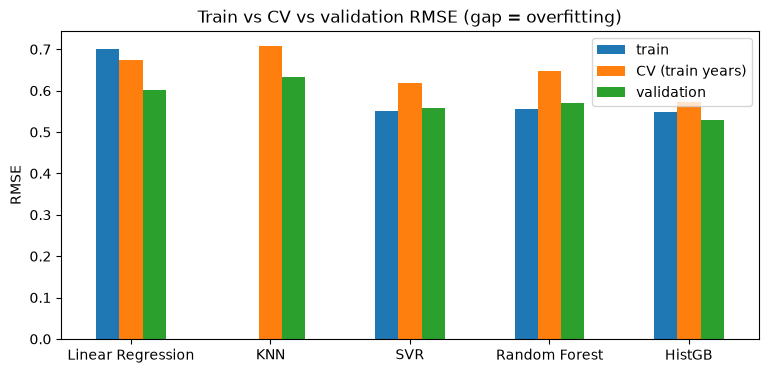

In [5]:
val_table = train.validation_table(tuned, X, y, masks, persistence)
val_table.to_csv(config.METRICS_DIR / "validation.csv")
display(val_table.drop(columns="n"))
m = val_table.drop(index="Persistence (baseline)")
ev.plot_overfitting(m["train_rmse"], m["cv_rmse"], m["rmse"], "09_overfitting")
plt.show()

## 4. Test set — evaluated once
Each family is refit on train+val with its tuned settings.

Linear Regression  refit + test in    2 s
KNN                refit + test in    2 s
SVR                refit + test in  112 s
Random Forest      refit + test in  102 s
HistGB             refit + test in   19 s


,rmse,mae,r2,storm_rmse,storm_mae
Persistence (baseline),0.862,0.643,0.566,1.368,1.059
Linear Regression,0.671,0.505,0.737,1.489,1.019
KNN,0.674,0.513,0.734,1.408,1.191
SVR,0.609,0.461,0.784,1.101,0.835
Random Forest,0.612,0.473,0.781,1.006,0.766
HistGB,0.585,0.445,0.800,0.876,0.650


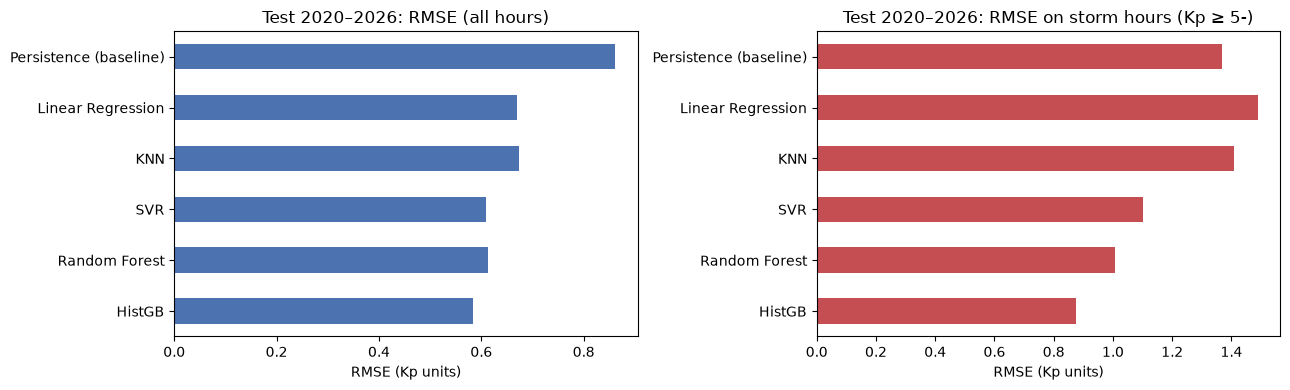

In [6]:
test_table, test_preds, test_models = train.test_evaluation(tuned, X, y, masks, persistence, fast=FAST)
test_table.to_csv(config.METRICS_DIR / "test.csv")
display(test_table.drop(columns="n"))
ev.plot_model_comparison(test_table, "Test 2020–2026", "10_model_comparison")
plt.show()

0-3      4  5 (G1)  6 (G2)  7+ (G3-G5)
Persistence (baseline) MAE   0.609  0.856   0.968   1.287       1.205
                       bias  0.065 -0.442  -0.622  -0.822      -0.932
Linear Regression      MAE   0.468  0.697   0.793   1.014       2.217
                       bias  0.129 -0.446  -0.475  -0.462       1.164
KNN                    MAE   0.461  0.803   1.022   1.438       1.717
                       bias -0.035 -0.700  -0.979  -1.422      -1.710
SVR                    MAE   0.436  0.586   0.678   0.919       1.538
                       bias  0.075 -0.293  -0.476  -0.791      -1.524
Random Forest          MAE   0.450  0.611   0.686   0.915       0.970
                       bias  0.110 -0.363  -0.502  -0.794      -0.838
HistGB                 MAE   0.428  0.544   0.589   0.769       0.794
                       bias  0.130 -0.231  -0.346  -0.604      -0.630

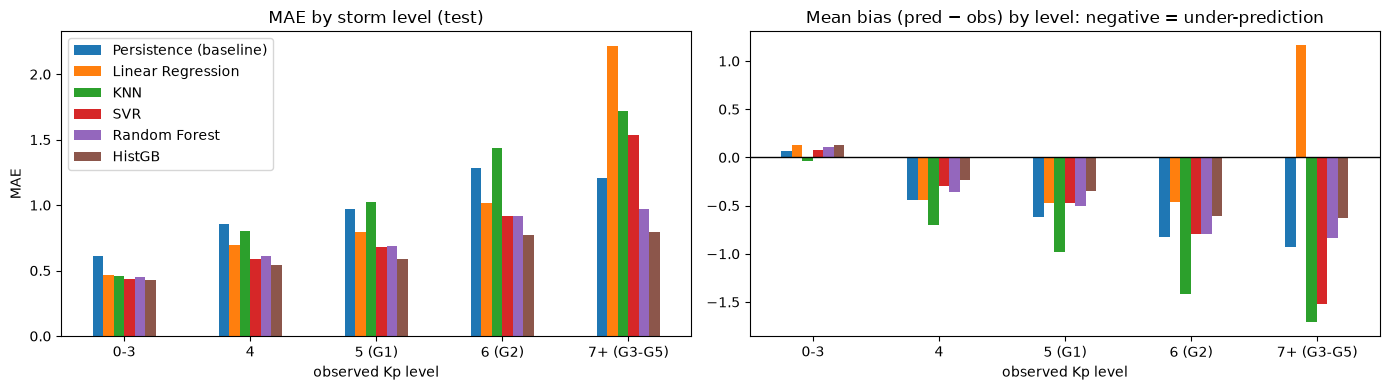

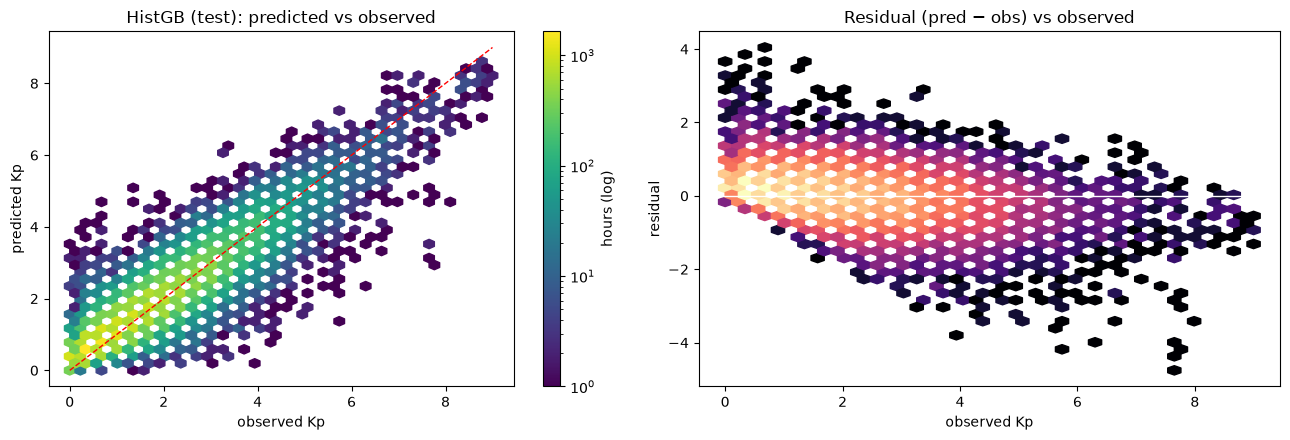

In [7]:
y_test = y[masks["test"]]
levels = ev.error_by_level(y_test, test_preds)
levels.to_csv(config.METRICS_DIR / "test_error_by_level.csv")
display(levels)
ev.plot_error_by_level(levels, "11_error_by_level")
plt.show()
ev.plot_pred_vs_actual(y_test, test_preds["HistGB"], "HistGB (test)", "12_pred_vs_actual")
plt.show()

## 5. Ablation: storm weighting (w = 1 + Kp/3)
Does up-weighting storm hours reduce storm under-prediction, and at what cost overall?

In [8]:
abl_table, abl_preds = train.weighting_ablation(tuned["HistGB"]["best_params"], X, y, masks, fast=FAST)
abl_table.to_csv(config.METRICS_DIR / "ablation_weighting.csv")
display(abl_table.drop(columns="n"))
ev.error_by_level(y_test, abl_preds)

,rmse,mae,r2,storm_rmse,storm_mae
HistGB (unweighted),0.585,0.445,0.80,0.876,0.650
HistGB (weighted 1+Kp/3),0.599,0.460,0.79,0.839,0.622


0-3      4  5 (G1)  6 (G2)  7+ (G3-G5)
HistGB (unweighted)      MAE   0.428  0.544   0.589   0.769       0.794
                         bias  0.130 -0.231  -0.346  -0.604      -0.630
HistGB (weighted 1+Kp/3) MAE   0.448  0.529   0.569   0.732       0.739
                         bias  0.192 -0.182  -0.303  -0.556      -0.577

## 6. What does the model rely on?
Permutation importance of the train-only HistGB on the validation years (how much RMSE worsens when one feature is shuffled).

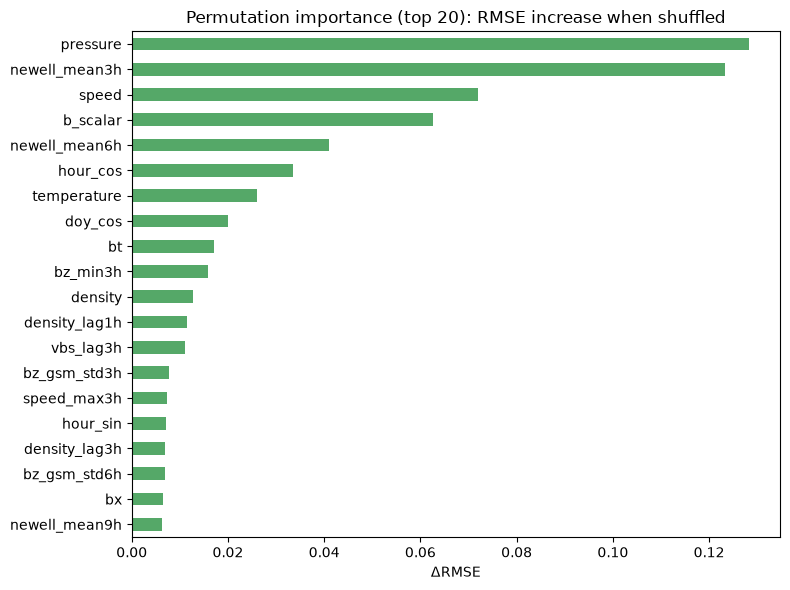

pressure         0.128
newell_mean3h    0.123
speed            0.072
b_scalar         0.063
newell_mean6h    0.041
hour_cos         0.034
temperature      0.026
doy_cos          0.020
bt               0.017
bz_min3h         0.016
density          0.013
density_lag1h    0.011
vbs_lag3h        0.011
bz_gsm_std3h     0.008
speed_max3h      0.007
dtype: float64

In [9]:
val = masks["val"]
_, importance = ev.plot_permutation_importance(tuned["HistGB"]["estimator"], X[val], y[val], "13_feature_importance")
plt.show()
importance.head(15).round(4)

## 7. Case study: May 2024 storm (model trained only on 1998–2019)

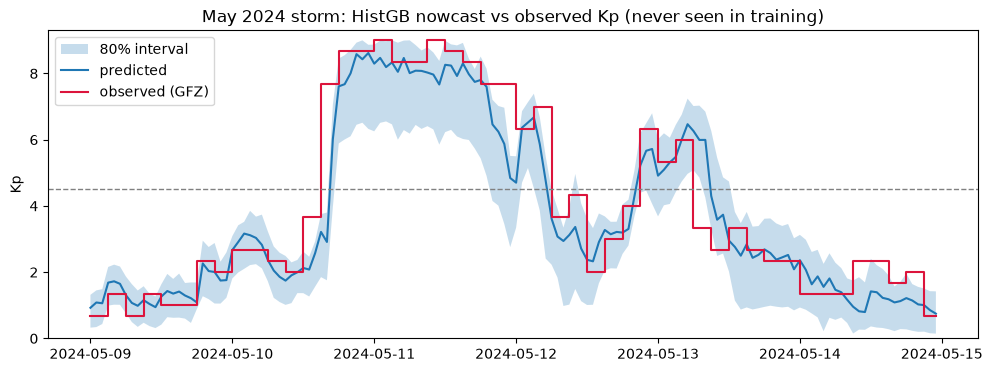

80% interval coverage on test: 77.0%


In [10]:
case = train.fit_bundle(tuned["HistGB"]["best_params"], X, y, masks["train"] | masks["val"], fast=FAST)
band = predict_with_interval(case, X[masks["test"]])
ev.plot_storm_case(y_test, band["kp_pred"], band["kp_lo"], band["kp_hi"], "2024-05-09", "2024-05-14",
                   "May 2024 storm: HistGB nowcast vs observed Kp (never seen in training)", "14_may2024_nowcast")
plt.show()
cov = ((y_test >= band["kp_lo"]) & (y_test <= band["kp_hi"])).mean()
print(f"80% interval coverage on test: {cov:.1%}")

## 8. Production model
HistGB (chosen for accuracy, small size, native NaN handling, quantile intervals) trained on all definitive data **up to the start of the last 6 months**; those 6 months are the validation-gate holdout that the weekly retrain will use. Saved as `models/tormenta_vYYYYMMDD.joblib` + `models/current.joblib`.

In [11]:
bundle, gate = train.fit_production(tuned["HistGB"]["best_params"], X, y, fast=FAST)
if FAST:
    print("FAST mode: not saving the model.")
else:
    version = train.save_bundle(bundle, test_table.loc["HistGB"].to_dict(), gate)
    print("Saved", version)
pd.Series(gate)

Saved tormenta_v20261028


rmse                                               0.581
mae                                                0.455
r2                                                 0.817
storm_rmse                                         0.702
storm_mae                                          0.542
n                                                   4417
coverage_80                                        0.783
holdout        2025-07-10 23:00:00 → 2026-01-10 23:00:00
dtype: object